# 1.1 Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from pathlib import Path

# 1.2 Load Modeling Dataset

In [2]:
data_path = Path("../data/processed/nba_modeling_dataset.csv")

game_level = pd.read_csv(
    data_path,
    dtype={"GAME_ID": str},
    parse_dates=["GAME_DATE"]
)

print("Dataset shape:", game_level.shape)
print("Unique games:", game_level["GAME_ID"].nunique())
print("Seasons:", game_level["SEASON"].nunique())

display(game_level.head())

Dataset shape: (13209, 29)
Unique games: 13209
Seasons: 11


,GAME_ID,SEASON,GAME_DATE,IS_NEUTRAL_SITE,HOME_TEAM_ID,HOME_TEAM_ABBREVIATION,HOME_REST_DAYS,HOME_IS_B2B,HOME_IS_3IN4,HOME_GAMES_LAST_7D,...,AWAY_GAMES_LAST_7D,AWAY_CONSECUTIVE_ROAD_GAMES,AWAY_TRAVEL_DISTANCE_KM,AWAY_WL,AWAY_PTS,HOME_WIN,POINT_DIFF,HOME_REST_DAYS_CAPPED,AWAY_REST_DAYS_CAPPED,IS_COVID_RESTART
0,0021400001,2014-15,2014-10-28,0,1610612740,NOP,NaN,0,0,0,...,0,1,NaN,L,84,1,17,NaN,NaN,0
1,0021400002,2014-15,2014-10-28,0,1610612759,SAS,NaN,0,0,0,...,0,1,NaN,L,100,1,1,NaN,NaN,0
2,0021400003,2014-15,2014-10-28,0,1610612747,LAL,NaN,0,0,0,...,0,1,NaN,W,108,0,-18,NaN,NaN,0
3,0021400004,2014-15,2014-10-29,0,1610612766,CHA,NaN,0,0,0,...,0,1,NaN,L,106,1,2,NaN,NaN,0
4,0021400005,2014-15,2014-10-29,0,1610612754,IND,NaN,0,0,0,...,0,1,NaN,L,91,1,12,NaN,NaN,0


# 1.3 Dataset Overview

In [3]:
print("Dataset shape:", game_level.shape)

print("\nColumn information:")
game_level.info()

print("\nMissing values:")
missing_values = game_level.isna().sum()
display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nGames per season:")
display(
    game_level.groupby("SEASON")
    .size()
    .to_frame("Game Count")
)


Dataset shape: (13209, 29)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 13209 entries, 0 to 13208
Data columns (total 29 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   GAME_ID                      13209 non-null  str           
 1   SEASON                       13209 non-null  str           
 2   GAME_DATE                    13209 non-null  datetime64[us]
 3   IS_NEUTRAL_SITE              13209 non-null  int64         
 4   HOME_TEAM_ID                 13209 non-null  int64         
 5   HOME_TEAM_ABBREVIATION       13209 non-null  str           
 6   HOME_REST_DAYS               13042 non-null  float64       
 7   HOME_IS_B2B                  13209 non-null  int64         
 8   HOME_IS_3IN4                 13209 non-null  int64         
 9   HOME_GAMES_LAST_7D           13209 non-null  int64         
 10  HOME_CONSECUTIVE_ROAD_GAMES  13209 non-null  int64         
 11  HOME

,Missing Count
HOME_REST_DAYS,167
HOME_TRAVEL_DISTANCE_KM,167
HOME_REST_DAYS_CAPPED,167
AWAY_REST_DAYS,163
AWAY_TRAVEL_DISTANCE_KM,163
AWAY_REST_DAYS_CAPPED,163



Games per season:


,Game Count
SEASON,
2014-15,1230
2015-16,1230
2016-17,1230
2017-18,1230
2018-19,1230
2019-20,1059
2020-21,1080
2021-22,1230
2022-23,1230


# 1.4 Descriptive Statistics

In [4]:
summary_variables = [
    "HOME_REST_DAYS",
    "AWAY_REST_DAYS",
    "HOME_IS_B2B",
    "AWAY_IS_B2B",
    "HOME_IS_3IN4",
    "AWAY_IS_3IN4",
    "HOME_GAMES_LAST_7D",
    "AWAY_GAMES_LAST_7D",
    "HOME_TRAVEL_DISTANCE_KM",
    "AWAY_TRAVEL_DISTANCE_KM",
    "AWAY_CONSECUTIVE_ROAD_GAMES",
    "HOME_WIN",
    "POINT_DIFF"
]

summary_stats = game_level[summary_variables].describe().T

display(summary_stats.round(2))


,count,mean,std,min,25%,50%,75%,max
HOME_REST_DAYS,13042.0,1.31,4.40,0.0,1.00,1.00,1.00,145.00
AWAY_REST_DAYS,13046.0,1.15,4.03,0.0,1.00,1.00,1.00,144.00
HOME_IS_B2B,13209.0,0.14,0.35,0.0,0.00,0.00,0.00,1.00
AWAY_IS_B2B,13209.0,0.23,0.42,0.0,0.00,0.00,0.00,1.00
HOME_IS_3IN4,13209.0,0.25,0.43,0.0,0.00,0.00,0.00,1.00
AWAY_IS_3IN4,13209.0,0.29,0.45,0.0,0.00,0.00,1.00,1.00
HOME_GAMES_LAST_7D,13209.0,3.05,0.88,0.0,3.00,3.00,4.00,5.00
AWAY_GAMES_LAST_7D,13209.0,3.07,0.87,0.0,3.00,3.00,4.00,5.00
HOME_TRAVEL_DISTANCE_KM,13042.0,613.37,906.97,0.0,0.00,0.00,1060.09,8317.82
AWAY_TRAVEL_DISTANCE_KM,13046.0,1140.31,800.87,0.0,576.28,975.88,1528.63,7356.58


# 1.5 Exploratory Visualizations

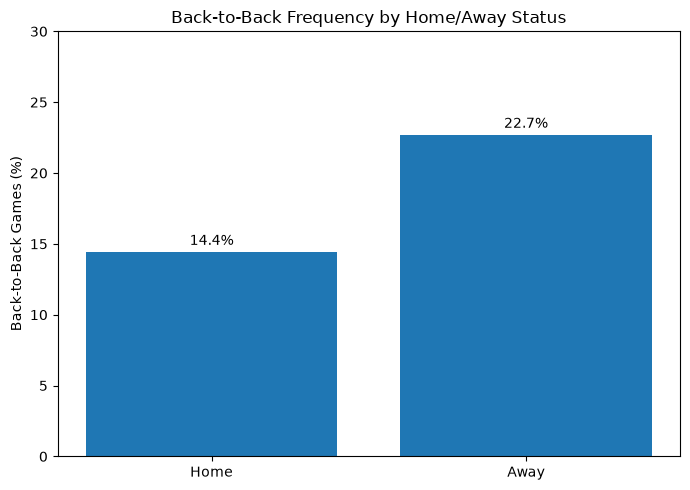

In [5]:
b2b_rates = pd.Series({
    "Home": game_level["HOME_IS_B2B"].mean() * 100,
    "Away": game_level["AWAY_IS_B2B"].mean() * 100
})

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    b2b_rates.index,
    b2b_rates.values
)

ax.set_title("Back-to-Back Frequency by Home/Away Status")
ax.set_ylabel("Back-to-Back Games (%)")
ax.set_ylim(0, 30)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


# 2.1 H1: Back-to-Back Effects

In [6]:
home_b2b_summary = (
    game_level.groupby("HOME_IS_B2B")
    .agg(
        Games=("HOME_WIN", "size"),
        Win_Rate=("HOME_WIN", "mean"),
        Average_Point_Differential=("POINT_DIFF", "mean")
    )
)

away_b2b_summary = (
    game_level.assign(
        AWAY_WIN=1 - game_level["HOME_WIN"],
        AWAY_POINT_DIFF=-game_level["POINT_DIFF"]
    )
    .groupby("AWAY_IS_B2B")
    .agg(
        Games=("AWAY_WIN", "size"),
        Win_Rate=("AWAY_WIN", "mean"),
        Average_Point_Differential=("AWAY_POINT_DIFF", "mean")
    )
)

home_b2b_summary.index = ["Non-B2B", "B2B"]
away_b2b_summary.index = ["Non-B2B", "B2B"]

print("Home Teams:")
display(home_b2b_summary.round(3))

print("Away Teams:")
display(away_b2b_summary.round(3))


Home Teams:


,Games,Win_Rate,Average_Point_Differential
Non-B2B,11303,0.572,2.448
B2B,1906,0.531,0.792


Away Teams:


,Games,Win_Rate,Average_Point_Differential
Non-B2B,10211,0.446,-1.759
B2B,2998,0.390,-3.741


## 2.1.1 Statistical Significance Tests

In [7]:
test_results = []

for location, summary, b2b_col, outcome_cols in [
    ("Home", game_level, "HOME_IS_B2B", ["HOME_WIN", "POINT_DIFF"]),
    ("Away", game_level.assign(
        AWAY_WIN=1 - game_level["HOME_WIN"],
        AWAY_POINT_DIFF=-game_level["POINT_DIFF"]
    ), "AWAY_IS_B2B", ["AWAY_WIN", "AWAY_POINT_DIFF"])
]:
    for outcome in outcome_cols:
        non_b2b = summary.loc[
            summary[b2b_col] == 0, outcome
        ].dropna()

        b2b = summary.loc[
            summary[b2b_col] == 1, outcome
        ].dropna()

        t_stat, p_value = stats.ttest_ind(
            b2b,
            non_b2b,
            equal_var=False
        )

        test_results.append({
            "Location": location,
            "Outcome": outcome,
            "B2B_Mean": b2b.mean(),
            "Non_B2B_Mean": non_b2b.mean(),
            "Difference": b2b.mean() - non_b2b.mean(),
            "T_Statistic": t_stat,
            "P_Value": p_value
        })

h1_test_results = pd.DataFrame(test_results)

display(h1_test_results.round(4))


,Location,Outcome,B2B_Mean,Non_B2B_Mean,Difference,T_Statistic,P_Value
0,Home,HOME_WIN,0.5310,0.5723,-0.0414,-3.3514,0.0008
1,Home,POINT_DIFF,0.7922,2.4482,-1.6560,-4.5626,0.0000
2,Away,AWAY_WIN,0.3899,0.4465,-0.0566,-5.5567,0.0000
3,Away,AWAY_POINT_DIFF,-3.7415,-1.7594,-1.9821,-6.6891,0.0000


# 2.2 H2: Travel and Back-to-Back

In [8]:
away_b2b_games = game_level.loc[
    (game_level["AWAY_IS_B2B"] == 1)
    & game_level["AWAY_TRAVEL_DISTANCE_KM"].notna()
].copy()

away_b2b_games["AWAY_WIN"] = (
    1 - away_b2b_games["HOME_WIN"]
)

away_b2b_games["AWAY_POINT_DIFF"] = (
    -away_b2b_games["POINT_DIFF"]
)

away_b2b_games["TRAVEL_GROUP"] = pd.qcut(
    away_b2b_games["AWAY_TRAVEL_DISTANCE_KM"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

h2_travel_summary = (
    away_b2b_games.groupby(
        "TRAVEL_GROUP",
        observed=True
    )
    .agg(
        Games=("AWAY_WIN", "size"),
        Average_Travel_KM=("AWAY_TRAVEL_DISTANCE_KM", "mean"),
        Win_Rate=("AWAY_WIN", "mean"),
        Average_Point_Differential=("AWAY_POINT_DIFF", "mean")
    )
)

display(h2_travel_summary.round(3))


,Games,Average_Travel_KM,Win_Rate,Average_Point_Differential
TRAVEL_GROUP,,,,
Low,1000,317.895,0.394,-3.497
Medium,999,775.429,0.394,-3.656
High,999,1327.160,0.381,-4.072


## 2.2.1 Travel and Back-to-Back Interaction

In [9]:
h2_data = game_level.loc[
    game_level["AWAY_TRAVEL_DISTANCE_KM"].notna()
].copy()

h2_data["AWAY_POINT_DIFF"] = -h2_data["POINT_DIFF"]

h2_data["AWAY_TRAVEL_1000KM"] = (
    h2_data["AWAY_TRAVEL_DISTANCE_KM"] / 1000
)

h2_model = smf.ols(
    formula=(
        "AWAY_POINT_DIFF ~ "
        "AWAY_IS_B2B * AWAY_TRAVEL_1000KM"
    ),
    data=h2_data
).fit(cov_type="HC3")

print(h2_model.summary())


                            OLS Regression Results                            
Dep. Variable:        AWAY_POINT_DIFF   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     15.65
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           3.70e-10
Time:                        08:17:57   Log-Likelihood:                -53312.
No. Observations:               13046   AIC:                         1.066e+05
Df Residuals:                   13042   BIC:                         1.067e+05
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

# 2.3 H3: Schedule Density

In [10]:
home_density = game_level[
    [
        "HOME_GAMES_LAST_7D",
        "HOME_WIN",
        "POINT_DIFF"
    ]
].rename(columns={
    "HOME_GAMES_LAST_7D": "GAMES_LAST_7D",
    "HOME_WIN": "WIN",
    "POINT_DIFF": "POINT_DIFFERENTIAL"
})

away_density = game_level[
    [
        "AWAY_GAMES_LAST_7D",
        "HOME_WIN",
        "POINT_DIFF"
    ]
].copy()

away_density["HOME_WIN"] = 1 - away_density["HOME_WIN"]
away_density["POINT_DIFF"] = -away_density["POINT_DIFF"]

away_density = away_density.rename(columns={
    "AWAY_GAMES_LAST_7D": "GAMES_LAST_7D",
    "HOME_WIN": "WIN",
    "POINT_DIFF": "POINT_DIFFERENTIAL"
})

density_data = pd.concat(
    [home_density, away_density],
    ignore_index=True
)

h3_density_summary = (
    density_data.groupby("GAMES_LAST_7D")
    .agg(
        Games=("WIN", "size"),
        Win_Rate=("WIN", "mean"),
        Average_Point_Differential=("POINT_DIFFERENTIAL", "mean")
    )
)

display(h3_density_summary.round(3))


,Games,Win_Rate,Average_Point_Differential
GAMES_LAST_7D,,,
0,665,0.498,-0.026
1,805,0.516,0.568
2,2956,0.526,0.832
3,13769,0.503,0.093
4,8219,0.484,-0.502
5,4,0.250,-13.750


## 2.3.1 Schedule Density Regression

In [11]:
home_h3 = game_level[
    ["HOME_GAMES_LAST_7D", "POINT_DIFF", "SEASON"]
].copy()

home_h3.columns = ["GAMES_LAST_7D", "POINT_DIFFERENTIAL", "SEASON"]
home_h3["IS_HOME"] = 1

away_h3 = game_level[
    ["AWAY_GAMES_LAST_7D", "POINT_DIFF", "SEASON"]
].copy()

away_h3.columns = ["GAMES_LAST_7D", "POINT_DIFFERENTIAL", "SEASON"]
away_h3["POINT_DIFFERENTIAL"] = -away_h3["POINT_DIFFERENTIAL"]
away_h3["IS_HOME"] = 0

h3_data = pd.concat([home_h3, away_h3], ignore_index=True)

h3_data["DENSITY_GROUP"] = (
    h3_data["GAMES_LAST_7D"]
    .clip(upper=4)
    .astype(int)
)

h3_model = smf.ols(
    "POINT_DIFFERENTIAL ~ C(DENSITY_GROUP, Treatment(reference=2)) + IS_HOME + C(SEASON)",
    data=h3_data
).fit(cov_type="HC3")

print(h3_model.summary())


                            OLS Regression Results                            
Dep. Variable:     POINT_DIFFERENTIAL   R-squared:                       0.024
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     42.63
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          5.53e-125
Time:                        08:17:57   Log-Likelihood:            -1.0798e+05
No. Observations:               26418   AIC:                         2.160e+05
Df Residuals:                   26402   BIC:                         2.161e+05
Df Model:                          15                                         
Covariance Type:                  HC3                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------

# 2.4 H4: Schedule Fairness

In [12]:
home_fairness = game_level[
    [
        "SEASON",
        "HOME_TEAM_ID",
        "HOME_TEAM_ABBREVIATION",
        "HOME_IS_B2B",
        "HOME_IS_3IN4",
        "HOME_GAMES_LAST_7D",
        "HOME_TRAVEL_DISTANCE_KM"
    ]
].copy()

home_fairness.columns = [
    "SEASON",
    "TEAM_ID",
    "TEAM",
    "IS_B2B",
    "IS_3IN4",
    "GAMES_LAST_7D",
    "TRAVEL_DISTANCE_KM"
]

away_fairness = game_level[
    [
        "SEASON",
        "AWAY_TEAM_ID",
        "AWAY_TEAM_ABBREVIATION",
        "AWAY_IS_B2B",
        "AWAY_IS_3IN4",
        "AWAY_GAMES_LAST_7D",
        "AWAY_TRAVEL_DISTANCE_KM"
    ]
].copy()

away_fairness.columns = home_fairness.columns

fairness_data = pd.concat(
    [home_fairness, away_fairness],
    ignore_index=True
)

team_season_fairness = (
    fairness_data.groupby(["SEASON", "TEAM_ID", "TEAM"])
    .agg(
        Games=("IS_B2B", "size"),
        B2B_Games=("IS_B2B", "sum"),
        Three_in_Four_Games=("IS_3IN4", "sum"),
        Average_Games_Last_7D=("GAMES_LAST_7D", "mean"),
        Total_Travel_KM=("TRAVEL_DISTANCE_KM", "sum")
    )
    .reset_index()
)

print("Team-season observations:", len(team_season_fairness))

display(team_season_fairness.head(10))


Team-season observations: 330


,SEASON,TEAM_ID,TEAM,Games,B2B_Games,Three_in_Four_Games,Average_Games_Last_7D,Total_Travel_KM
0,2014-15,1610612737,ATL,82,21,30,3.182927,66635.211479
1,2014-15,1610612738,BOS,82,18,29,3.256098,76967.002080
2,2014-15,1610612739,CLE,82,20,27,3.158537,56474.533768
3,2014-15,1610612740,NOP,82,20,26,3.170732,76597.066665
4,2014-15,1610612741,CHI,82,20,24,3.085366,60372.238029
5,2014-15,1610612742,DAL,82,17,22,3.036585,70265.804708
6,2014-15,1610612743,DEN,82,21,29,3.170732,84123.243047
7,2014-15,1610612744,GSW,82,19,25,3.158537,79462.535138
8,2014-15,1610612745,HOU,82,20,27,3.073171,78851.320349
9,2014-15,1610612746,LAC,82,20,29,3.170732,72684.277156


## 2.4.1 Schedule Burden Variation

In [13]:
fairness_metrics = [
    "B2B_Games",
    "Three_in_Four_Games",
    "Average_Games_Last_7D",
    "Total_Travel_KM"
]

fairness_variation = (
    team_season_fairness.groupby("SEASON")[fairness_metrics]
    .agg(["min", "max", "mean", "std"])
    .round(2)
)

display(fairness_variation)


B2B_Games                  Three_in_Four_Games                   \
              min max   mean   std                 min max   mean   std   
SEASON                                                                    
2014-15        16  22  19.33  1.56                  22  32  26.73  2.41   
2015-16        14  20  17.80  1.77                  21  30  24.57  2.27   
2016-17        14  19  16.37  1.33                  19  29  23.93  2.60   
2017-18        13  16  14.43  0.82                  10  23  19.13  2.75   
2018-19        12  15  13.27  0.94                  14  23  18.23  2.05   
2019-20         7  13  10.50  1.28                  12  19  15.77  2.11   
2020-21        13  17  15.23  1.41                  18  32  24.27  3.44   
2021-22        11  17  14.10  1.42                  16  27  20.73  2.97   
2022-23        12  16  13.37  1.19                  17  24  20.37  2.04   
2023-24        13  17  14.07  0.94                  16  27  20.47  2.56   
2024-25        13  17  15.00  1.20                  18  25  22.00  1.80   

        Average_Games_Last_7D                   Total_Travel_KM             \
                          min   max  mean   std             min        max   
SEASON                                                                       
2014-15                  3.04  3.26  3.15  0.05        56474.53  100186.50   
2015-16                  3.07  3.20  3.13  0.03        56284.15   91683.82   
2016-17                  3.04  3.21  3.13  0.04        59831.07   92870.64   
2017-18                  2.88  3.11  2.98  0.06        60721.56   87273.23   
2018-19                  2.90  3.10  2.98  0.05        56988.50   87277.16   
2019-20                  2.75  3.06  2.91  0.07        39277.52   76210.70   
2020-21                  3.12  3.33  3.21  0.06        47474.95   69926.22   
2021-22                  2.95  3.15  3.05  0.05        56622.50   82152.92   
2022-23                  2.95  3.11  3.05  0.04        53780.27   79193.93   
2023-24                  2.96  3.10  3.04  0.03        55991.54   83281.85   
2024-25                  2.96  3.13  3.05  0.04        56390.48   91082.36   

                            
             mean      std  
SEASON                      
2014-15  73412.22  9975.59  
2015-16  71789.57  8939.05  
2016-17  74965.29  9436.69  
2017-18  73730.89  8241.82  
2018-19  72687.00  7976.19  
2019-20  60418.41  8239.42  
2020-21  59832.64  5963.63  
2021-22  69017.21  7551.77  
2022-23  66554.37  7355.56  
2023-24  68986.62  6829.40  
2024-25  71142.83  7501.55

## 2.4.2 Identify Teams with Highest and Lowest Schedule Burden

In [14]:
latest_fairness = team_season_fairness.loc[
    team_season_fairness["SEASON"] == "2024-25"
].copy()

print("Highest B2B Burden:")
display(
    latest_fairness.nlargest(5, "B2B_Games")[
        ["TEAM", "Games", "B2B_Games", "Three_in_Four_Games"]
    ]
)

print("Lowest B2B Burden:")
display(
    latest_fairness.nsmallest(5, "B2B_Games")[
        ["TEAM", "Games", "B2B_Games", "Three_in_Four_Games"]
    ]
)

print("Highest Travel Burden:")
display(
    latest_fairness.nlargest(5, "Total_Travel_KM")[
        ["TEAM", "Total_Travel_KM"]
    ].round(2)
)

print("Lowest Travel Burden:")
display(
    latest_fairness.nsmallest(5, "Total_Travel_KM")[
        ["TEAM", "Total_Travel_KM"]
    ].round(2)
)


Highest B2B Burden:


,TEAM,Games,B2B_Games,Three_in_Four_Games
300,ATL,82,17,24
308,HOU,82,17,20
309,LAC,82,17,22
302,CLE,82,16,23
303,NOP,82,16,22


Lowest B2B Burden:


,TEAM,Games,B2B_Games,Three_in_Four_Games
301,BOS,82,13,21
304,CHI,82,13,18
305,DAL,82,13,20
320,POR,82,13,23
307,GSW,82,14,24


Highest Travel Burden:


,TEAM,Total_Travel_KM
322,SAS,91082.36
321,SAC,82371.52
320,POR,81877.76
313,MIN,81368.13
307,GSW,78723.41


Lowest Travel Burden:


,TEAM,Total_Travel_KM
328,DET,56390.48
324,TOR,60149.79
327,WAS,61928.42
329,CHA,62257.62
318,PHI,62325.73
